# 4. Variance and peak height

This notebook follows Sec. 3.1 of Paper I, the first rung of the halo layer.
Every fit of the layer — sixteen multiplicity functions, six bias fits, the peak-height concentrations — reads the cosmology through one curve, $\sigma(M)$.
We build it, its slope and the peak height, and differentiate it with respect to the ten parameters, ending on the figure of the variance.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

import ggah_mod.halos as H
from ggah_mod import DIFFERENTIABLE
from ggah_mod.cosmology import PLANCK18, make_pk
from ggah_mod.halos.field import make_field

pk = make_pk("emu_pk")
c = PLANCK18
M = np.logspace(10.0, 16.0, 80 if FAST else 160)     # h^-1 Msun
K = np.logspace(-4.0, 2.0, 512)                      # h Mpc^-1
mj, kj = jnp.asarray(M), jnp.asarray(K)
near = lambda arr, value: int(np.argmin(np.abs(np.asarray(arr) - value)))

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = False


## From a radius to a mass

The variance of notebook 03 is specialised to a mass through the Lagrangian radius of the sphere that contained it before collapse (Eq. 31):

$$\sigma^2(M) = \frac{1}{2\pi^2}\int P_{\rm cb}(k)\,W^2\big(kR(M)\big)k^2\,{\rm d}k,\qquad R(M) = \left(\frac{3M}{4\pi\bar\rho_{\rm cb}}\right)^{1/3}.$$

Haloes form out of the CDM+baryon field, so both the spectrum and the density are the cold ones.
The halo boundaries of a spherical-overdensity mass definition use the total matter density instead; the two densities differ by 0.46 per cent at $\sum m_\nu = 0.06$ eV.

In [2]:
print(f"rho_cb = {float(c.rho_cold):.5e},  rho_m = {float(c.rho_matter):.5e} (h^-1 Msun)/(h^-1 Mpc)^3, "
      f"ratio - 1 = {float(c.rho_matter / c.rho_cold) - 1:.2%}")

pk_cb = pk.pk_cb(kj, 0.0, c)
H.check_k_support(M, K, c.rho_cold)            # refuses a k grid too narrow for these masses
sig = np.asarray(H.sigma_of_mass(mj, kj, pk_cb, c.rho_cold))
R = np.asarray(H.lagrangian_radius(mj, c.rho_cold))
nu = H.DELTA_C / sig
for mm in (1e10, 1e12, 1e14, 1e16):
    i = near(M, mm)
    print(f"M = {M[i]:8.2e}  R = {R[i]:7.3f} Mpc/h  sigma = {sig[i]:6.4f}  nu = {nu[i]:6.3f}")

rho_cb = 8.71133e+10,  rho_m = 8.75073e+10 (h^-1 Msun)/(h^-1 Mpc)^3, ratio - 1 = 0.45%


M = 1.00e+10  R =   0.301 Mpc/h  sigma = 3.7804  nu =  0.446
M = 1.00e+12  R =   1.399 Mpc/h  sigma = 2.1373  nu =  0.789
M = 1.00e+14  R =   6.495 Mpc/h  sigma = 0.9394  nu =  1.795
M = 1.00e+16  R =  30.149 Mpc/h  sigma = 0.2691  nu =  6.266


## The slope and the peak height

The mass function needs ${\rm d}\ln\sigma/{\rm d}\ln M = \tfrac13\,{\rm d}\ln\sigma/{\rm d}\ln R$ (Eq. 32), which `dln_sigma_dln_mass` takes by automatic differentiation rather than by differencing $\sigma(M)$.
The peak height is $\nu = \delta_{\rm c}/\sigma$ with $\delta_{\rm c} = 1.686$ (Eq. 33); $\nu = 1$ defines the characteristic mass $M_\star$.

In [3]:
dlns = np.asarray(H.dln_sigma_dln_mass(mj, kj, pk_cb, c.rho_cold))
fd = np.gradient(np.log(sig), np.log(M))
print(f"max |autodiff - finite difference| of dln sigma/dln M = {np.max(np.abs(dlns - fd)[2:-2]):.1e}")
M_star = float(np.interp(H.DELTA_C, sig[::-1], M[::-1]))
print(f"M_star = {M_star:.2e} h^-1 Msun   (paper: 4.6e12)")

from ggah_mod.cosmology import sigma8, sigma_tophat
s8_cold = float(sigma_tophat(pk_cb, kj, 8.0))
s8_tot = float(sigma8(pk.pk(kj, 0.0, c), kj))
print(f"at R = 8 Mpc/h: sigma on P_cb = {s8_cold:.3f}, sigma_8 on P_m = {s8_tot:.3f}   (paper: 0.817, 0.813)")

max |autodiff - finite difference| of dln sigma/dln M = 1.2e-05
M_star = 4.60e+12 h^-1 Msun   (paper: 4.6e12)


at R = 8 Mpc/h: sigma on P_cb = 0.817, sigma_8 on P_m = 0.813   (paper: 0.817, 0.813)


## Derivatives

The mass is held fixed, so the cosmology moves the radius $R(M)$ through $\bar\rho_{\rm cb}$ as well as the spectrum.
Both are inside the function we differentiate.

In [4]:
g = {}
for p in T.DPARAMS:
    v0 = float(getattr(c, p))
    scale = v0 if p in T.DLOG else 1.0

    def lnsig(v, p=p):
        cc = c.replace(**{p: v})
        return jnp.log(H.sigma_of_mass(mj, kj, pk.pk_cb(kj, 0.0, cc), cc.rho_cold))

    g[p] = np.asarray(jax.jacfwd(lnsig)(v0)) * scale

lo, hi = near(M, 1e12), near(M, 1e15)
print(f"{'':10s}{'1e12':>10s}{'1e15':>10s}")
for p in T.DPARAMS:
    print(f"{p:10s}{g[p][lo]:+10.4g}{g[p][hi]:+10.4g}")

                1e12      1e15
Omega_m       +1.214   +0.8732
Omega_b      -0.3629    -0.264
h              +1.39    +1.028
sum_mnu      -0.0155   -0.0138
T_cmb        -0.0164   -0.0118
n_s           +1.046   +0.1646
ln10A_s         +0.5      +0.5
w0           -0.2477   -0.2477
wa          -0.07614  -0.07612
Omega_k      -0.9591   -0.9595


## The figure

Fig. 5 of the paper.
Panel (a) is $\sigma(M)$ at the fiducial in black, with $\Omega_{\rm m}$ and $\Omega_k$ moved either side; the top axis is the Lagrangian radius and the right axis the peak height.
Panel (b) is $\partial\ln\sigma/\partial\theta$ for the ten parameters.

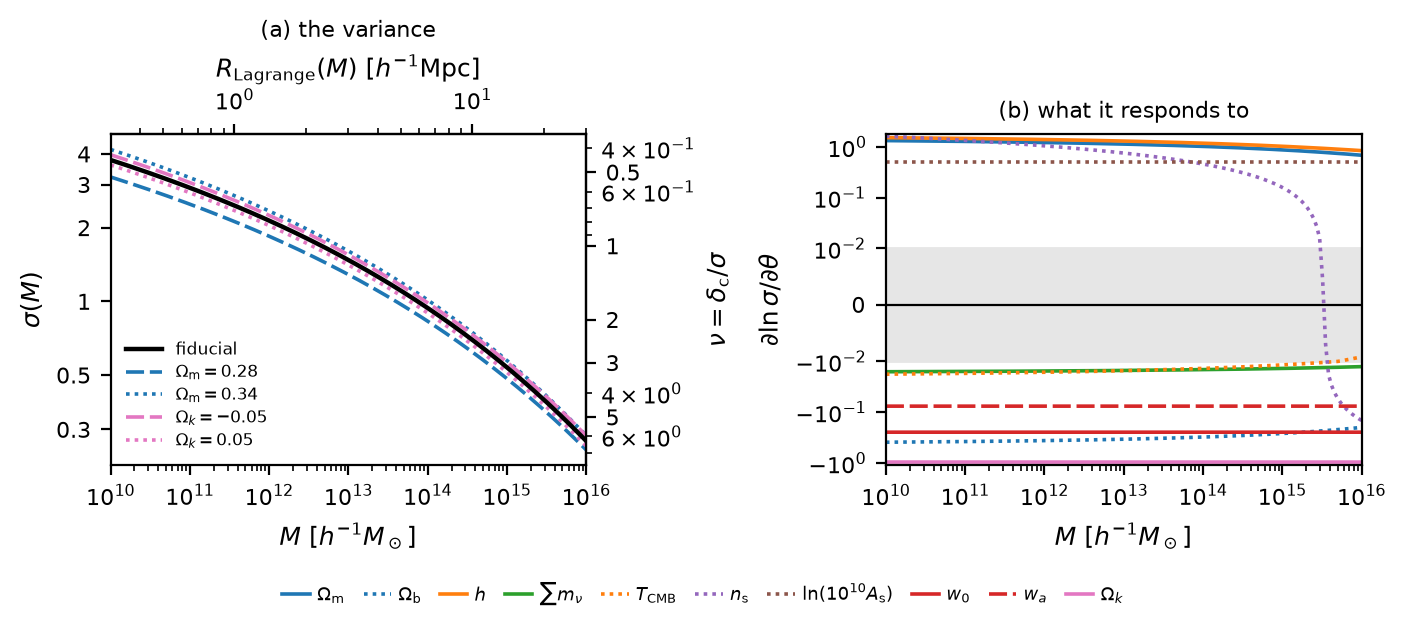

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(7.1, 3.1))
ax[0].grid(False)
ax[1].grid(False)
ax[0].loglog(M, sig, "k", lw=1.6, zorder=3, label="fiducial")
for p, v, ls in (("Omega_m", 0.28, (0, (5, 1.6))), ("Omega_m", 0.34, (0, (1, 1.4))),
                 ("Omega_k", -0.05, (0, (5, 1.6))), ("Omega_k", 0.05, (0, (1, 1.4)))):
    cv = c.replace(**{p: v})
    ax[0].loglog(M, H.sigma_of_mass(mj, kj, pk.pk_cb(kj, 0.0, cv), cv.rho_cold),
                 color=T.DSTYLE[p][0], ls=ls, lw=1.3, label=T.TEX[p][:-1] + rf" = {v:g}$")
ax[0].legend(fontsize=6.0, loc="lower left", frameon=False, handlelength=2.2, labelspacing=0.35)
rho = float(c.rho_cold)
ax[0].set_xlim(M[0], M[-1])
sec = ax[0].secondary_xaxis("top", functions=(lambda m: (3 * np.maximum(m, 1e-300) / (4 * np.pi * rho)) ** (1 / 3),
                                              lambda r: 4 / 3 * np.pi * np.maximum(r, 1e-300) ** 3 * rho))
sec.set_xlabel(r"$R_{\rm Lagrange}(M)\ [h^{-1}\mathrm{Mpc}]$")
sec.grid(False)
nax = ax[0].secondary_yaxis("right", functions=(lambda s: H.DELTA_C / np.maximum(s, 1e-300),
                                                lambda n: H.DELTA_C / np.maximum(n, 1e-300)))
nax.set_ylabel(r"$\nu = \delta_{\rm c}/\sigma$")
nax.grid(False)
ax[0].set(xlabel=r"$M\ [h^{-1}M_\odot]$", ylabel=r"$\sigma(M)$", title="(a) the variance")
ax[0].set_yticks([0.3, 0.5, 1.0, 2.0, 3.0, 4.0])
ax[0].set_yticks([], minor=True)
ax[0].set_yticklabels(["0.3", "0.5", "1", "2", "3", "4"])
nax.set_yticks([0.5, 1.0, 2.0, 3.0, 5.0])
nax.set_yticklabels(["0.5", "1", "2", "3", "5"])

LIN = 1e-2
ax[1].axhspan(-LIN, LIN, color="0.90", zorder=0)
for p in T.DPARAMS:
    colour, ls = T.DSTYLE[p]
    ax[1].plot(M, g[p], color=colour, ls=ls, lw=1.3, label=T.TEX[p])
ax[1].axhline(0.0, color="k", lw=0.8)
ax[1].set_xscale("log")
ax[1].set_yscale("symlog", linthresh=LIN)
ax[1].set(xlabel=r"$M\ [h^{-1}M_\odot]$", ylabel=r"$\partial\ln\sigma/\partial\theta$",
          title="(b) what it responds to", xlim=(M[0], M[-1]))
handles, labels = ax[1].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=6.6, ncol=10, loc="lower center", bbox_to_anchor=(0.5, -0.015),
           frameon=False, handlelength=1.5, columnspacing=1.0, handletextpad=0.4)
fig.tight_layout(rect=(0, 0.055, 1, 1))
T.save_figure(fig, "fig_variance")

## Exercises

1. Recompute $\sigma(M)$ on $P_{\rm m}$ and $\bar\rho_{\rm m}$ instead of the cold field, at $\sum m_\nu = 0.06$ and 0.3 eV. How large is the difference at $10^{14}\,h^{-1}{\rm M}_\odot$, and how would a fit to cluster counts absorb it?
2. Shrink the $k$ grid to $10^{-2} < k < 10\,h\,{\rm Mpc}^{-1}$ and call `H.check_k_support`. Which masses does it refuse, and why?
3. Plot $M_\star(z)$ for $0 < z < 3$. How fast does the characteristic mass fall?

Next: notebook 05, the abundance and the bias of haloes.